# 강판 표면 결함 분류 (단순화 버전 v2 - 성능 복원 + 개선)

1. 데이터 불러오기 → 2. 열 정리 → 3. 데이터 살펴보기 → 4. 학습/테스트 나누기
5. 모델 4개 튜닝 → 6. 상위 2개 앙상블 + 규제 조정 + 클래스별 확률 보정
7. 테스트 평가 → 8. 오분류 확인 → 9. 변수 중요도 → 10. 저장 및 예측 → 11. 추가 실험

**v1 대비 바뀐 점 (성능에 영향을 준 부분)**
- 결함 이름을 0~6 숫자로 바꿔 학습 → 원래 노트북과 같은 학습/테스트 분할, 같은 교차검증 조각
- 열 순서를 원래 노트북과 동일하게 유지 → 같은 튜닝 결과
- 원래 실험에서 유일하게 효과가 있던 LightGBM 규제(reg_lambda)를 본 모델에 반영 (교차검증으로 확인 후)
- 원래 노트북의 클래스별 확률 보정을 단순한 반복문으로 복원

In [1]:
# ============================================================
# 0. 라이브러리 불러오기 및 기본 설정
# ============================================================

import numpy as np                  # 숫자 계산
import pandas as pd                 # 표(데이터프레임) 다루기
import matplotlib.pyplot as plt     # 그래프 그리기
import joblib                       # 모델 파일로 저장 / 불러오기
import warnings
warnings.filterwarnings("ignore")   # 경고 메시지 숨기기

from scipy.stats import chi2_contingency                 # 카이제곱 검정
from sklearn import set_config
from sklearn.base import clone                           # 모델 설정만 복사 (학습 전 상태)
from sklearn.model_selection import train_test_split     # 학습/테스트 나누기
from sklearn.model_selection import StratifiedKFold      # 클래스 비율 유지 교차검증
from sklearn.model_selection import RepeatedStratifiedKFold  # 교차검증 여러 번 반복
from sklearn.model_selection import RandomizedSearchCV   # 하이퍼파라미터 무작위 탐색
from sklearn.model_selection import cross_val_score      # 교차검증 점수
from sklearn.model_selection import cross_val_predict    # 교차검증 방식으로 예측값 얻기
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import VotingClassifier            # 여러 모델 확률 평균(앙상블)
from sklearn.inspection import permutation_importance    # 변수 중요도
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트 (맥은 "AppleGothic")
plt.rcParams["axes.unicode_minus"] = False      # 그래프에서 마이너스(-) 깨짐 방지
pd.set_option("display.max_columns", None)      # 표의 모든 열 보이기

# 모델을 셀 출력으로 보여줄 때 HTML 대신 글자로만 표시
# (한글 Windows에서 sklearn이 HTML용 파일을 cp949로 읽다가 UnicodeDecodeError가 나는 문제 방지)
set_config(display="text")

RANDOM_STATE = 42   # 이 숫자를 고정하면 실행할 때마다 같은 결과가 나온다
N_ITER = 20         # 모델마다 시험해 볼 하이퍼파라미터 조합 수 (오래 걸리면 줄이기)

In [2]:
# ============================================================
# 1. 데이터 불러오기
# ============================================================

df = pd.read_csv("steel_plates_faults.csv")       # CSV 파일 읽기

print("데이터 크기:", df.shape)                    # (행 수, 열 수)
print("결측치 개수:", df.isna().sum().sum())       # 빈 칸 개수 (0이면 정상)
print("중복 행 개수:", df.duplicated().sum())      # 완전히 같은 행 개수
df.head()                                         # 앞 5행 보기

데이터 크기: (1941, 34)
결측치 개수: 0
중복 행 개수: 0


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [3]:
# ============================================================
# 2. 열 정리 - 원-핫 열을 하나의 열로 합치기
# ============================================================

# 강종을 나타내는 2개 열, 결함 종류를 나타내는 7개 열
steel_cols = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
fault_cols = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]

# 각 행에 강종과 결함이 정확히 하나씩만 표시돼 있는지 확인 (가로 합이 1이어야 함)
print("강종이 하나로 정해진 행만 있는가:", (df[steel_cols].sum(axis=1) == 1).all())
print("결함이 하나로 정해진 행만 있는가:", (df[fault_cols].sum(axis=1) == 1).all())

# 결함 7개 열 → 값이 1인 열의 이름을 꺼내서 'Fault_Type' 열 하나로 만든다
df["Fault_Type"] = df[fault_cols].idxmax(axis=1)

# 강종 2개 열 → A300이면 0, A400이면 1 ('TypeOfSteel_A400' 값과 같다)
# 원래 강종 열이 있던 자리에 끼워 넣는다 (열 순서가 바뀌면 모델 결과가 조금 달라지기 때문)
position = df.columns.get_loc("TypeOfSteel_A300")
df.insert(position, "Steel_Type", df["TypeOfSteel_A400"])

df[["Steel_Type", "Fault_Type"]].head()

강종이 하나로 정해진 행만 있는가: True
결함이 하나로 정해진 행만 있는가: True


,Steel_Type,Fault_Type
0,0,Pastry
1,0,Pastry
2,0,Pastry
3,1,Pastry
4,1,Pastry


In [4]:
# ============================================================
# 3. 데이터 살펴보기 - 결함 분포, 강종과 결함의 관계
# ============================================================

# 결함 종류별 개수 (클래스 불균형 확인)
print("[결함 종류별 개수]")
print(df["Fault_Type"].value_counts())

# 결함 종류 × 강종 교차표
table = pd.crosstab(df["Fault_Type"], df["Steel_Type"])
print("\n[결함 종류 × 강종 (0=A300, 1=A400)]")
print(table)

# 카이제곱 검정: 강종과 결함 종류가 서로 관련이 있는가?
chi2, p_value, dof, expected = chi2_contingency(table)

# Cramér's V: 관련성의 세기 (0 = 관련 없음, 1 = 완전히 관련)
cramers_v = np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))

print(f"\n카이제곱 = {chi2:.1f}, p값 = {p_value:.4f}, Cramér's V = {cramers_v:.3f}")

[결함 종류별 개수]
Fault_Type
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

[결함 종류 × 강종 (0=A300, 1=A400)]
Steel_Type      0    1
Fault_Type            
Bumps         279  123
Dirtiness       9   46
K_Scatch        1  390
Other_Faults  266  407
Pastry         49  109
Stains          1   71
Z_Scratch     172   18

카이제곱 = 667.0, p값 = 0.0000, Cramér's V = 0.586


In [5]:
# ============================================================
# 4. 입력(X) / 정답(y) 만들고 학습 80% / 테스트 20% 로 나누기
# ============================================================

# 입력 변수: 원래 원-핫 열과 정답 열을 뺀 나머지 (Steel_Type 은 포함)
X = df.drop(columns=steel_cols + fault_cols + ["Fault_Type"])

# 정답: 결함 이름을 0~6 숫자로 바꿔서 사용
#   0=Pastry, 1=Z_Scratch, 2=K_Scatch, 3=Stains, 4=Dirtiness, 5=Bumps, 6=Other_Faults
# (원래 노트북과 같은 숫자를 써야 학습/테스트 분할과 교차검증 조각이 똑같이 나온다)
fault_to_num = {name: i for i, name in enumerate(fault_cols)}
y = df["Fault_Type"].map(fault_to_num)

# stratify=y : 학습/테스트 모두 결함 비율이 원래 데이터와 같게 나눈다
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("학습 데이터:", X_train.shape, "/ 테스트 데이터:", X_test.shape)

# 5-Fold 교차검증: 학습 데이터를 5조각으로 나눠 돌아가며 검증 (튜닝, 확률 보정에 사용)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 5-Fold × 3회 반복 = 15번: 작은 차이를 비교할 때 사용 (규제 조정, 추가 실험)
# random_state 를 고정했으므로 몇 번을 써도 항상 같은 15개 조각으로 나뉜다
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

학습 데이터: (1552, 26) / 테스트 데이터: (389, 26)


In [6]:
# ============================================================
# 5-1. 사용할 모델과 시험해 볼 하이퍼파라미터 범위
# ============================================================

models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    "CatBoost": CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0,
                                   allow_writing_files=False),
}

# class_weight="balanced" : 개수가 적은 결함에 가중치를 더 줘서 불균형을 보정
params = {
    "Random Forest": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 700, 1000],
        "learning_rate": [0.02, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 22, 31],
        "max_depth": [-1, 5, 7, 10],
        "min_child_samples": [5, 10, 20, 33],
        "subsample": [0.6, 0.8, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0, 0.01, 1, 5],
        "class_weight": [None, "balanced"],
    },
    "CatBoost": {
        "iterations": [300, 500, 700],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}

In [7]:
# ============================================================
# 5-2. 하이퍼파라미터 튜닝 (학습 데이터 5-Fold 교차검증, Macro F1 기준)
# ============================================================
# Macro F1 : 결함 7종의 F1을 단순 평균. 개수가 적은 결함도 똑같이 중요하게 본다.

best_models = {}    # 모델 이름 → 튜닝된 모델
results = []        # 결과 표를 만들 목록

for name in models:
    print(name, "튜닝 중...")

    search = RandomizedSearchCV(
        models[name],          # 튜닝할 모델
        params[name],          # 시험할 하이퍼파라미터 범위
        n_iter=N_ITER,         # 무작위로 고를 조합 수
        scoring="f1_macro",    # 평가 기준
        cv=cv,                 # 5-Fold 교차검증
        random_state=RANDOM_STATE,
        n_jobs=-1,             # CPU 코어 모두 사용
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_            # 가장 좋았던 설정의 모델
    results.append([name, search.best_score_, search.best_params_])
    print(f"  CV Macro F1 = {search.best_score_:.4f}")

# 결과를 표로 만들고 점수 높은 순으로 정렬
result_df = pd.DataFrame(results, columns=["모델", "CV Macro F1", "최적 파라미터"])
result_df = result_df.sort_values("CV Macro F1", ascending=False).reset_index(drop=True)
result_df

Random Forest 튜닝 중...
  CV Macro F1 = 0.7974
Extra Trees 튜닝 중...
  CV Macro F1 = 0.8166
LightGBM 튜닝 중...
  CV Macro F1 = 0.8168
CatBoost 튜닝 중...
  CV Macro F1 = 0.8156


,모델,CV Macro F1,최적 파라미터
0,LightGBM,0.816797,"{'subsample_freq': 1, 'subsample': 0.8, 'reg_l..."
1,Extra Trees,0.816626,"{'n_estimators': 300, 'min_samples_split': 5, ..."
2,CatBoost,0.815581,"{'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iter..."
3,Random Forest,0.797442,"{'n_estimators': 300, 'min_samples_split': 5, ..."


In [8]:
# ============================================================
# 6-1. 상위 2개 모델 앙상블 (소프트 보팅 = 두 모델의 예측 확률 평균)
# ============================================================

top2 = result_df["모델"].head(2).tolist()      # 점수가 가장 높은 모델 2개 이름
print("앙상블에 쓸 모델:", top2)

ensemble = VotingClassifier(
    estimators=[(name, best_models[name]) for name in top2],   # (이름, 모델) 목록
    voting="soft",                                             # 확률을 평균해서 결정
)

# 반복 교차검증(15번)으로 기준 점수 계산 → 6-2 에서 이 점수와 비교
base_scores = cross_val_score(ensemble, X_train, y_train, cv=cv_rep,
                              scoring="f1_macro", n_jobs=-1)
print(f"앙상블 CV Macro F1 = {base_scores.mean():.4f} ± {base_scores.std():.4f}")

앙상블에 쓸 모델: ['LightGBM', 'Extra Trees']
앙상블 CV Macro F1 = 0.8196 ± 0.0190


In [9]:
# ============================================================
# 6-2. LightGBM 규제 조정 (원래 노트북 실험에서 유일하게 "효과 있음"이 나온 방법)
# ============================================================
# reg_lambda 가 클수록 모델이 학습 데이터를 덜 외운다 (과적합 방지).
# 학습 데이터 교차검증 15번에서 기준 앙상블과 같은 조각끼리 비교하고,
# "평균 +0.005 이상 & 15번 중 10번 이상 나아짐" 일 때만 바꾼다. (테스트 데이터는 안 봄)

best_value = None          # 채택할 reg_lambda 값 (None = 바꾸지 않음)
best_scores = base_scores  # 지금까지 가장 좋은 15개 점수

if "LightGBM" in top2:
    for value in [1, 5, 20]:
        # 앙상블 구성원을 복사하고 LightGBM 의 reg_lambda 만 바꾸기
        members = []
        for name in top2:
            model = clone(best_models[name])
            if name == "LightGBM":
                model.set_params(reg_lambda=value)
            members.append((name, model))
        trial = VotingClassifier(estimators=members, voting="soft")

        scores = cross_val_score(trial, X_train, y_train, cv=cv_rep,
                                 scoring="f1_macro", n_jobs=-1)
        diff = scores - base_scores                     # 같은 조각끼리 점수 차이
        print(f"reg_lambda={value:<3} {scores.mean():.4f} | 기준 대비 {diff.mean():+.4f} "
              f"| 나아진 조각 {(diff > 0).sum()}/15")

        # 기준을 넘고, 지금까지 찾은 값보다 좋으면 채택 후보로 저장
        if diff.mean() >= 0.005 and (diff > 0).sum() >= 10 and scores.mean() > best_scores.mean():
            best_value, best_scores = value, scores
else:
    print("LightGBM 이 앙상블에 없어서 건너뜀")

# 채택된 값이 있으면 best_models 의 LightGBM 설정을 바꾸고 앙상블을 다시 만든다
if best_value is not None:
    best_models["LightGBM"] = clone(best_models["LightGBM"]).set_params(reg_lambda=best_value)
    ensemble = VotingClassifier(
        estimators=[(name, best_models[name]) for name in top2], voting="soft")
    print(f"\n→ LightGBM reg_lambda={best_value} 채택")
else:
    print("\n→ 규제 조정 효과 없음, 튜닝 결과 그대로 사용")

reg_lambda=1   0.8211 | 기준 대비 +0.0015 | 나아진 조각 8/15
reg_lambda=5   0.8238 | 기준 대비 +0.0041 | 나아진 조각 10/15
reg_lambda=20  0.8229 | 기준 대비 +0.0033 | 나아진 조각 9/15

→ 규제 조정 효과 없음, 튜닝 결과 그대로 사용


In [10]:
# ============================================================
# 6-3. 클래스별 확률 보정
# ============================================================
# 예측 확률에 결함별 배율(weights)을 곱한 뒤 가장 큰 값을 예측으로 한다.
#   배율 > 1 : 그 결함을 더 자주 예측 (재현율 ↑, 정밀도 ↓)
#   배율 < 1 : 그 결함을 덜 예측
# 배율은 학습 데이터의 교차검증 예측(각 행을 학습에 쓰지 않은 모델의 예측)으로만 찾는다.

# 1) 교차검증 방식으로 학습 데이터 전체의 예측 확률 구하기
oof_proba = cross_val_predict(ensemble, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)

before = f1_score(y_train, oof_proba.argmax(axis=1), average="macro")   # 보정 전 점수

# 2) 결함 하나씩 배율을 0.5 ~ 3.0 사이로 바꿔 보며 Macro F1이 오르면 채택 (3바퀴 반복)
weights = np.ones(len(fault_cols))      # 처음에는 모든 배율 = 1 (보정 없음)
best = before
grid = np.round(np.arange(0.5, 3.01, 0.1), 2)

for round_num in range(3):
    for k in range(len(fault_cols)):            # 결함 하나씩
        for w in grid:                          # 배율 후보 하나씩
            trial = weights.copy()
            trial[k] = w
            pred = (oof_proba * trial).argmax(axis=1)
            score = f1_score(y_train, pred, average="macro")
            if score > best:                    # 좋아졌으면 바꾼 배율 유지
                best, weights = score, trial

print(f"보정 전 Macro F1 = {before:.4f} → 보정 후 = {best:.4f}")

# 3) 이 배율도 학습 데이터에 맞춘 값이라 조금 낙관적이다.
#    0.005 이상 좋아질 때만 사용하고, 아니면 배율을 모두 1로 되돌린다.
if best - before < 0.005:
    weights = np.ones(len(fault_cols))
    print("→ 보정 효과가 작아서 사용하지 않음")

print(pd.Series(weights, index=fault_cols, name="배율"))

# 앙상블을 학습 데이터 전체로 학습 (끝의 ; 는 셀 출력에 모델을 표시하지 않게 함)
ensemble.fit(X_train, y_train);

보정 전 Macro F1 = 0.8236 → 보정 후 = 0.8358
Pastry          2.2
Z_Scratch       0.5
K_Scatch        1.0
Stains          0.5
Dirtiness       1.9
Bumps           1.0
Other_Faults    1.0
Name: 배율, dtype: float64


In [11]:
# ============================================================
# 7. 테스트 데이터로 최종 평가 (테스트는 여기서 한 번만 사용)
# ============================================================

proba = ensemble.predict_proba(X_test)            # 결함별 예측 확률
y_pred = (proba * weights).argmax(axis=1)         # 배율을 곱한 뒤 가장 큰 결함 번호
y_test_arr = y_test.to_numpy()                    # 인덱스 없이 값만 꺼내기

print("정확도(Accuracy):", round(accuracy_score(y_test_arr, y_pred), 4))
print("Macro F1        :", round(f1_score(y_test_arr, y_pred, average="macro"), 4))
print("(참고) 보정 없이 :", round(f1_score(y_test_arr, proba.argmax(axis=1), average="macro"), 4))

# 부트스트랩 95% 신뢰구간
# 테스트 데이터를 복원 추출로 1000번 다시 뽑아 점수가 얼마나 흔들리는지 확인
rng = np.random.default_rng(RANDOM_STATE)
boot_scores = []
for i in range(1000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))   # 무작위로 행 번호 뽑기
    boot_scores.append(f1_score(y_test_arr[idx], y_pred[idx], average="macro"))

low, high = np.percentile(boot_scores, [2.5, 97.5])
print(f"Macro F1 95% 신뢰구간: [{low:.3f}, {high:.3f}]")

# 결함 종류별 정밀도 / 재현율 / F1 (숫자 대신 결함 이름으로 표시)
print(classification_report(y_test_arr, y_pred, labels=list(range(7)),
                            target_names=fault_cols, digits=4))

정확도(Accuracy): 0.8201
Macro F1        : 0.8349
(참고) 보정 없이 : 0.8264
Macro F1 95% 신뢰구간: [0.786, 0.876]
              precision    recall  f1-score   support

      Pastry     0.5918    0.9062    0.7160        32
   Z_Scratch     1.0000    0.8947    0.9444        38
    K_Scatch     0.9744    0.9744    0.9744        78
      Stains     0.9286    0.9286    0.9286        14
   Dirtiness     0.7500    0.8182    0.7826        11
       Bumps     0.7568    0.6914    0.7226        81
Other_Faults     0.7969    0.7556    0.7757       135

    accuracy                         0.8201       389
   macro avg     0.8283    0.8527    0.8349       389
weighted avg     0.8305    0.8201    0.8217       389



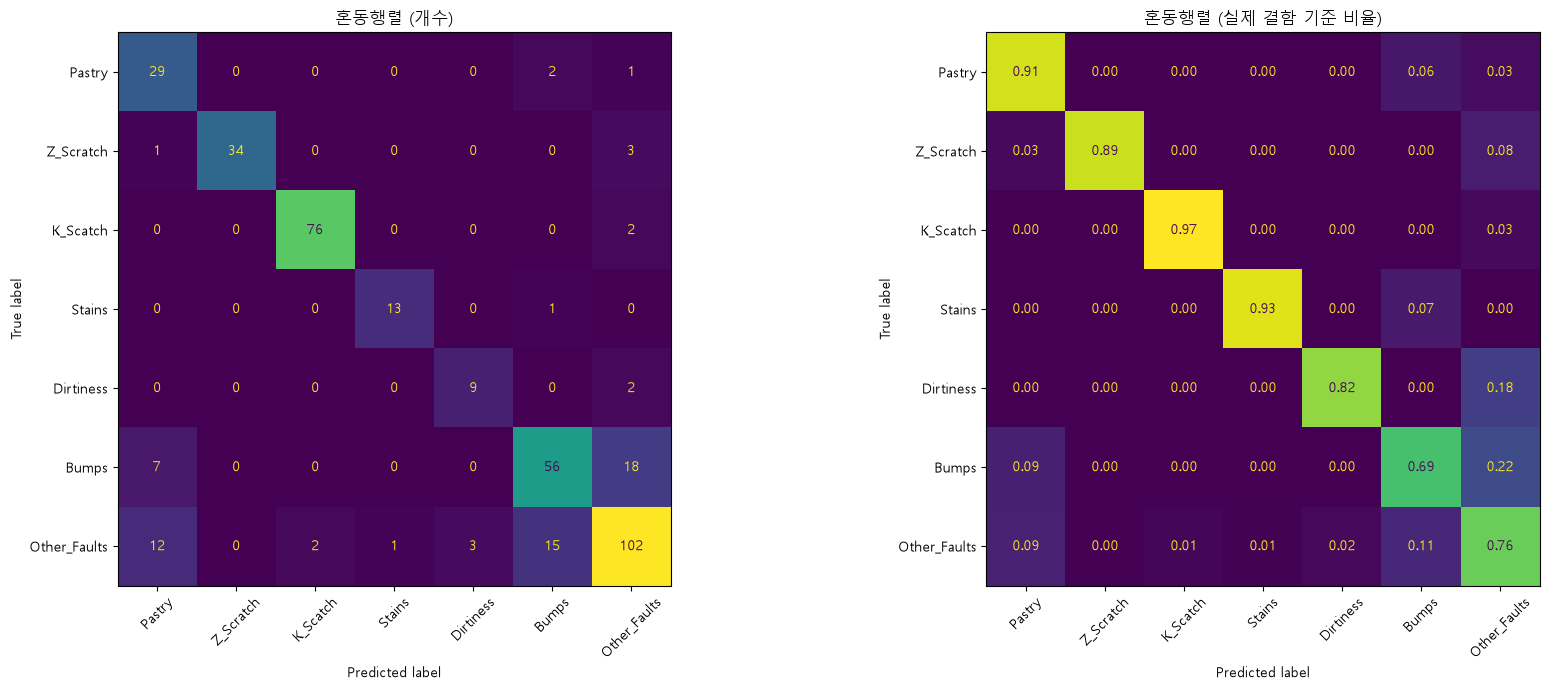

In [12]:
# ============================================================
# 8-1. 혼동행렬 - 어떤 결함을 어떤 결함으로 헷갈리는지
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 왼쪽: 개수
ConfusionMatrixDisplay.from_predictions(
    y_test_arr, y_pred, display_labels=fault_cols, ax=axes[0],
    xticks_rotation=45, colorbar=False)
axes[0].set_title("혼동행렬 (개수)")

# 오른쪽: 실제 결함 기준 비율 (한 줄의 합 = 1)
ConfusionMatrixDisplay.from_predictions(
    y_test_arr, y_pred, display_labels=fault_cols, normalize="true",
    values_format=".2f", ax=axes[1], xticks_rotation=45, colorbar=False)
axes[1].set_title("혼동행렬 (실제 결함 기준 비율)")

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# 8-2. 오분류 행 뽑기
# ============================================================

names = np.array(fault_cols)        # 숫자 → 결함 이름으로 바꿀 때 사용

# 테스트 결과 표: 실제 결함, 예측 결함, 확신도
test_result = pd.DataFrame({
    "실제": names[y_test_arr],
    "예측": names[y_pred],
    "확신도": proba.max(axis=1),
}, index=X_test.index)              # 인덱스 = 원본 데이터의 행 번호

# 실제와 예측이 다른 행만 골라내기
wrong = test_result[test_result["실제"] != test_result["예측"]]
print(f"오분류: {len(wrong)}개 / {len(test_result)}개 ({len(wrong) / len(test_result):.2%})")

# 자주 헷갈린 조합 (실제 → 예측)
print("\n[자주 헷갈린 조합]")
print(wrong.groupby(["실제", "예측"]).size().sort_values(ascending=False).head(10))

# 높은 확신으로 틀린 행 (라벨이 잘못됐을 수도 있으니 다시 확인해 볼 후보)
print("\n[확신도 높은 오분류 상위 10개]")
display(wrong.sort_values("확신도", ascending=False).head(10))

# 오분류 행 + 원본 열 전체를 파일로 저장 (엑셀에서 열 수 있게 utf-8-sig)
wrong.join(df).to_csv("misclassified_rows.csv", encoding="utf-8-sig")

오분류: 70개 / 389개 (17.99%)

[자주 헷갈린 조합]
실제            예측          
Bumps         Other_Faults    18
Other_Faults  Bumps           15
              Pastry          12
Bumps         Pastry           7
Z_Scratch     Other_Faults     3
Other_Faults  Dirtiness        3
Dirtiness     Other_Faults     2
K_Scatch      Other_Faults     2
Pastry        Bumps            2
Other_Faults  K_Scatch         2
dtype: int64

[확신도 높은 오분류 상위 10개]


,실제,예측,확신도
816,Dirtiness,Other_Faults,0.898402
1348,Other_Faults,Pastry,0.892518
871,Bumps,Other_Faults,0.871443
1395,Other_Faults,K_Scatch,0.850514
1196,Bumps,Other_Faults,0.834171
48,Pastry,Bumps,0.804874
1098,Bumps,Other_Faults,0.783499
1311,Other_Faults,Pastry,0.779614
869,Bumps,Other_Faults,0.757723
1088,Bumps,Other_Faults,0.755313


,변수,중요도,표준편차
10,Length_of_Conveyer,0.094670,0.013461
11,Steel_Type,0.081719,0.013504
12,Steel_Plate_Thickness,0.073255,0.013251
2,Y_Minimum,0.037015,0.008034
23,Orientation_Index,0.017113,0.009309
9,Maximum_of_Luminosity,0.014652,0.005982
4,Pixels_Areas,0.012873,0.004421
0,X_Minimum,0.012592,0.010105
8,Minimum_of_Luminosity,0.011960,0.009010
18,Edges_Y_Index,0.011759,0.007535


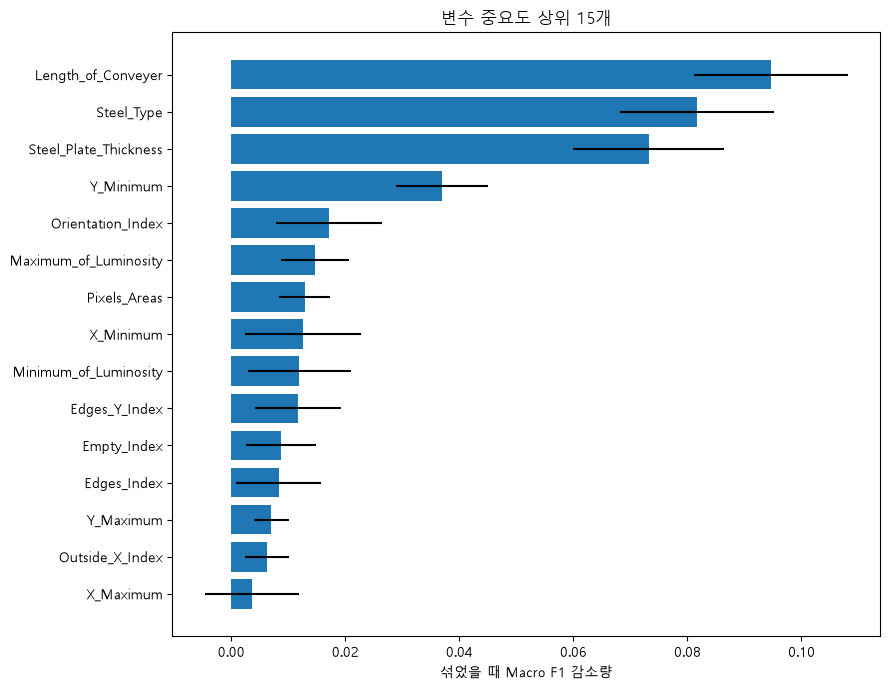

In [14]:
# ============================================================
# 9. 변수 중요도 (Permutation Importance)
# ============================================================
# 변수 하나의 값을 무작위로 섞었을 때 Macro F1이 얼마나 떨어지는지 측정.
# 많이 떨어질수록 모델이 그 변수에 많이 의존한다는 뜻.

# 배율 보정까지 포함한 Macro F1 을 계산하는 채점 함수
def weighted_f1(model, X_part, y_part):
    pred = (model.predict_proba(X_part) * weights).argmax(axis=1)
    return f1_score(y_part, pred, average="macro")

perm = permutation_importance(ensemble, X_test, y_test, scoring=weighted_f1,
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)

importance = pd.DataFrame({
    "변수": X.columns,
    "중요도": perm.importances_mean,     # 20번 섞은 결과의 평균
    "표준편차": perm.importances_std,    # 20번 섞은 결과의 흔들림
}).sort_values("중요도", ascending=False)

display(importance.head(15))

# 상위 15개 막대 그래프 (위에서부터 중요한 순서가 되도록 뒤집어서 그림)
top15 = importance.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top15["변수"], top15["중요도"], xerr=top15["표준편차"])
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.title("변수 중요도 상위 15개")
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# 10-1. 전체 데이터로 다시 학습하고 파일로 저장
# ============================================================
# 평가는 끝났으니 테스트 데이터까지 합친 전체 데이터로 학습해서 실제 사용할 모델을 만든다.

final_model = clone(ensemble)          # 같은 설정의 학습 전 앙상블
final_model.fit(X, y)                  # 전체 데이터로 학습

joblib.dump({"model": final_model,             # 모델
             "weights": weights,               # 클래스별 배율
             "columns": X.columns.tolist(),    # 입력 열 순서
             "fault_names": fault_cols},       # 0~6 번호의 결함 이름
            "steel_fault_model_simple.joblib")
print("저장 완료: steel_fault_model_simple.joblib")

저장 완료: steel_fault_model_simple.joblib


In [16]:
# ============================================================
# 10-2. 새 데이터 예측 함수
# ============================================================
# 원본 CSV와 같은 형식(TypeOfSteel_A300 / A400 열 포함)의 데이터를 넣으면 된다.

def predict_faults(new_data):
    saved = joblib.load("steel_fault_model_simple.joblib")     # 저장한 모델 불러오기

    data = new_data.copy()
    data["Steel_Type"] = data["TypeOfSteel_A400"]               # 2번 단계와 같은 처리
    X_new = data[saved["columns"]]                              # 학습 때와 같은 열, 같은 순서

    proba = saved["model"].predict_proba(X_new) * saved["weights"]   # 배율 적용
    proba = proba / proba.sum(axis=1, keepdims=True)                 # 합이 1이 되게 다시 맞춤

    result = pd.DataFrame(proba, columns=saved["fault_names"], index=new_data.index).round(3)
    result.insert(0, "예측 결함", np.array(saved["fault_names"])[proba.argmax(axis=1)])
    result.insert(1, "확신도", proba.max(axis=1).round(3))
    return result


# 동작 확인 (전체 데이터로 학습한 모델이라 이미 본 데이터 → 성능 확인용 아님)
sample = df.loc[X_test.index[:5]]
demo = predict_faults(sample)
demo.insert(0, "실제 결함", sample["Fault_Type"])
demo

,실제 결함,예측 결함,확신도,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
904,Bumps,Bumps,0.979,0.008,0.000,0.000,0.0,0.0,0.979,0.013
492,K_Scatch,K_Scatch,1.000,0.000,0.000,1.000,0.0,0.0,0.000,0.000
232,Z_Scratch,Z_Scratch,0.982,0.000,0.982,0.000,0.0,0.0,0.003,0.015
1093,Bumps,Bumps,0.862,0.018,0.000,0.004,0.0,0.0,0.862,0.117
803,Stains,Stains,1.000,0.000,0.000,0.000,1.0,0.0,0.000,0.000


## 11. 추가 실험 (선택)

학습 데이터에서만 교차검증 15번으로 비교합니다. 테스트 데이터는 7번에서 이미 봤기 때문에 쓰지 않습니다.
기준 모델은 6-2에서 규제 조정까지 반영된 앙상블이고, 확률 보정은 빼고 비교합니다.

**판정 기준:** 기준보다 평균 0.005 이상 높고, 15번 중 10번 이상 나아졌으면 "효과 있음".

In [17]:
# ============================================================
# 11-1. 실험 준비 - 기준 모델 점수
# ============================================================

exp_base = cross_val_score(ensemble, X_train, y_train, cv=cv_rep,
                           scoring="f1_macro", n_jobs=-1)
print(f"기준 모델: {exp_base.mean():.4f} ± {exp_base.std():.4f}")

experiment_scores = {"기준 모델": exp_base}    # 실험 이름 → 15개 점수


def compare(name, scores):
    """기준 모델과 같은 조각끼리 비교해서 결과를 출력하고 저장"""
    experiment_scores[name] = scores
    diff = scores - exp_base                      # 조각별 점수 차이
    better = (diff > 0).sum()                     # 나아진 조각 수
    print(f"{name:<28} {scores.mean():.4f} | 기준 대비 {diff.mean():+.4f} | "
          f"나아진 조각 {better}/15")

기준 모델: 0.8196 ± 0.0190


,변수,구분력(AUC),Bumps 중앙값,Other 중앙값
0,Square_Index,0.678526,7.500000e-01,0.53330
1,Steel_Type,0.654371,0.000000e+00,1.00000
2,Y_Minimum,0.651889,1.587172e+06,840983.00000
3,Y_Maximum,0.651884,1.587191e+06,841067.50000
4,Edges_Y_Index,0.642879,1.000000e+00,0.93750
5,Y_Perimeter,0.618119,1.500000e+01,22.00000
6,X_Perimeter,0.617821,1.700000e+01,25.00000
7,Empty_Index,0.615482,3.333000e-01,0.42565
8,Edges_Index,0.606602,4.485000e-01,0.31120
9,SigmoidOfAreas,0.595204,3.068000e-01,0.41945


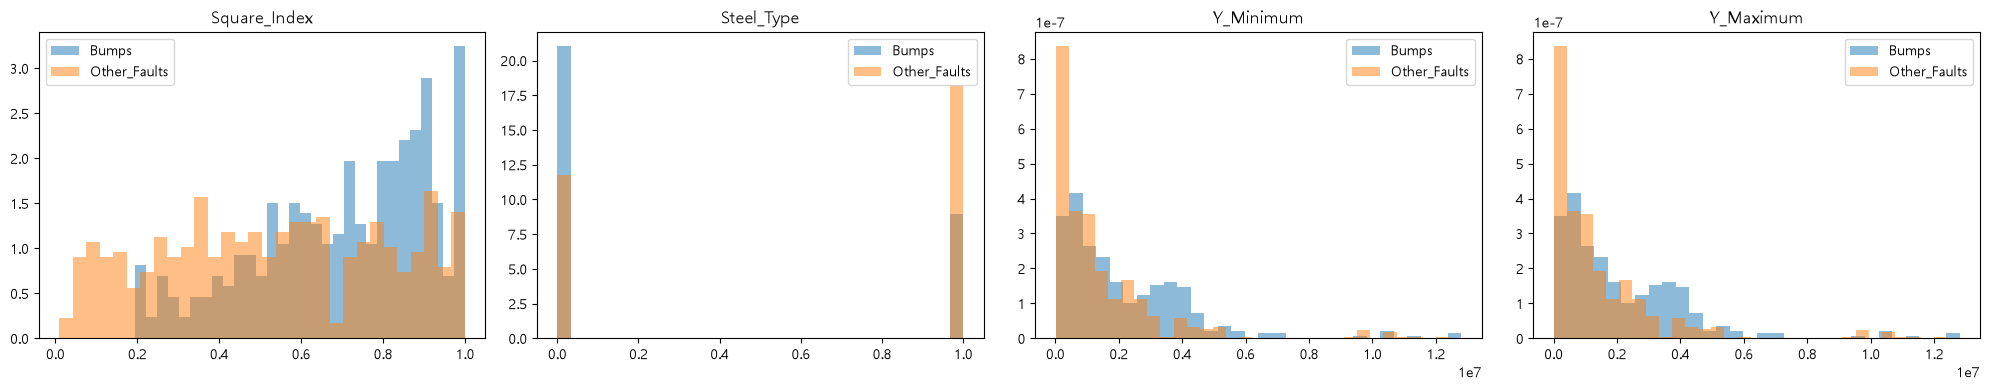

In [18]:
# ============================================================
# 11-2. 가장 많이 헷갈리는 Bumps vs Other_Faults - 어떤 변수가 둘을 가르나?
# ============================================================
# AUC : 변수 하나로 두 결함을 나눌 때의 성능 (0.5 = 못 나눔, 1.0 = 완벽히 나눔)

bumps, other = fault_to_num["Bumps"], fault_to_num["Other_Faults"]
mask = y_train.isin([bumps, other])                 # 두 결함만 고르기
X_bo = X_train[mask]
y_bo = (y_train[mask] == bumps).astype(int)         # Bumps = 1, Other_Faults = 0

rows = []
for col in X_bo.columns:
    auc = roc_auc_score(y_bo, X_bo[col])
    auc = max(auc, 1 - auc)                          # 방향과 상관없이 구분력만 보기
    rows.append([col, auc,
                 X_bo.loc[y_bo == 1, col].median(),  # Bumps 의 중앙값
                 X_bo.loc[y_bo == 0, col].median()]) # Other_Faults 의 중앙값

auc_df = pd.DataFrame(rows, columns=["변수", "구분력(AUC)", "Bumps 중앙값", "Other 중앙값"])
auc_df = auc_df.sort_values("구분력(AUC)", ascending=False).reset_index(drop=True)
display(auc_df.head(10))

# 구분력 상위 4개 변수의 분포 비교
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, auc_df["변수"].head(4)):
    ax.hist(X_bo.loc[y_bo == 1, col], bins=30, alpha=0.5, density=True, label="Bumps")
    ax.hist(X_bo.loc[y_bo == 0, col], bins=30, alpha=0.5, density=True, label="Other_Faults")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# 11-3. 오버샘플링 실험 - 개수가 적은 결함을 150개까지 늘리기
# ============================================================
# 필요 패키지: pip install imbalanced-learn
# imblearn 의 Pipeline 을 쓰면 교차검증의 '학습 조각'에만 오버샘플링이 적용되고
# '검증 조각'에는 적용되지 않는다 (데이터 누수 방지).
# SMOTENC : SMOTE 와 같지만 Steel_Type 같은 범주형 열은 0/1 값을 그대로 유지한다.

from imblearn.over_sampling import SMOTENC, RandomOverSampler
from imblearn.pipeline import Pipeline

# 학습 데이터에서 150개보다 적은 결함만 150개로 늘리도록 설정
counts = y_train.value_counts()
target = {k: 150 for k in counts.index if counts[k] < 150}
print("늘릴 결함:", {fault_cols[k]: v for k, v in target.items()})

steel_idx = X_train.columns.get_loc("Steel_Type")    # 범주형 열의 위치

samplers = {
    "RandomOverSampler (복제)": RandomOverSampler(sampling_strategy=target,
                                                 random_state=RANDOM_STATE),
    "SMOTE (보간)": SMOTENC(categorical_features=[steel_idx], sampling_strategy=target,
                            random_state=RANDOM_STATE),
}

for name, sampler in samplers.items():
    pipe = Pipeline([("sampler", sampler), ("model", ensemble)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv_rep,
                             scoring="f1_macro", n_jobs=-1)
    compare(name, scores)

늘릴 결함: {'Pastry': 150, 'Stains': 150, 'Dirtiness': 150}
RandomOverSampler (복제)       0.8187 | 기준 대비 -0.0009 | 나아진 조각 7/15
SMOTE (보간)                   0.8210 | 기준 대비 +0.0013 | 나아진 조각 7/15


## 11-5 ~ 11-9. 오분류 행을 활용한 실험

`misclassified_rows.csv`는 **테스트 데이터**의 오분류입니다. 이 행들을 보고 모델을 고친 뒤 같은 테스트로 다시 평가하면,
테스트에 맞춘 셈이 되어 점수가 실제보다 좋게 나옵니다. 그래서 아래 실험은 모두 다음 원칙을 따릅니다.

- **분석·아이디어**는 학습 데이터의 교차검증 예측(OOF) 오분류에서 얻는다 (테스트 오분류는 같은 패턴인지 확인용).
- **효과 판정**은 학습 데이터 교차검증 15번(`compare`)으로만 한다. 배율·가중치처럼 데이터로 정하는 값은
  교차검증의 학습 조각 안에서 다시 정한다 (중첩 검증).
- **라벨 수정**은 모델이 아니라 사람이 원본을 확인해서 한다.

| 실험 | 노리는 오분류 |
|---|---|
| 11-6 배율 보정 중첩 검증 | Pastry로 잘못 예측한 행 (테스트 오분류 70개 중 20개) |
| 11-7 Bumps/Other 전용 모델 | Bumps ↔ Other_Faults (33개) |
| 11-8 학습 가중치 조정 | 라벨이 의심되는 행, 어려운 행 |
| 11-9 라벨 재검토 목록 | 확신도 높은 오분류 |

In [20]:
# ============================================================
# 11-5. 학습 데이터 OOF 오분류 분석 - 테스트 오분류와 같은 패턴인가?
# ============================================================
# oof_proba : 6-3 에서 만든 학습 데이터 교차검증 예측 확률 (배율 적용 전)

y_tr = y_train.to_numpy()
oof_raw = oof_proba.argmax(axis=1)               # 배율 적용 전 예측
oof_pred = (oof_proba * weights).argmax(axis=1)  # 배율 적용 후 예측

oof_result = pd.DataFrame({"실제": names[y_tr], "예측": names[oof_pred]}, index=X_train.index)
oof_wrong = oof_result[oof_result["실제"] != oof_result["예측"]]
print(f"학습 데이터 OOF 오분류: {len(oof_wrong)}개 / {len(oof_result)}개 "
      f"({len(oof_wrong) / len(oof_result):.2%})")

# 학습(OOF)과 테스트에서 자주 헷갈린 조합 비교 (비율)
pair_cmp = pd.concat([
    oof_wrong.groupby(["실제", "예측"]).size().rename("학습 OOF"),
    wrong.groupby(["실제", "예측"]).size().rename("테스트"),
], axis=1).fillna(0)
pair_cmp = (pair_cmp / pair_cmp.sum()).sort_values("학습 OOF", ascending=False)
print("\n[자주 헷갈린 조합 - 전체 오분류 중 비율]")
display(pair_cmp.head(10).round(3))

# 배율 보정이 만든 오분류 vs 바로잡은 오분류
def scale_effect(y_true, raw, scaled):
    broke = (raw == y_true) & (scaled != y_true)     # 배율 때문에 틀려진 행
    fixed = (raw != y_true) & (scaled == y_true)     # 배율 덕분에 맞힌 행
    return broke, fixed

for label, yt, raw, scaled in [("학습 OOF", y_tr, oof_raw, oof_pred),
                               ("테스트", y_test_arr, proba.argmax(axis=1), y_pred)]:
    broke, fixed = scale_effect(yt, raw, scaled)
    print(f"\n[{label}] 배율 때문에 틀려진 행 {broke.sum()}개 / 배율 덕분에 맞힌 행 {fixed.sum()}개")
    print("  틀려진 행의 예측:", pd.Series(names[scaled[broke]]).value_counts().to_dict())
    print("  맞힌 행의 실제  :", pd.Series(names[yt[fixed]]).value_counts().to_dict())

학습 데이터 OOF 오분류: 303개 / 1552개 (19.52%)

[자주 헷갈린 조합 - 전체 오분류 중 비율]


학습 OOF    테스트
실제           예측                         
Bumps        Other_Faults   0.281  0.257
Other_Faults Bumps          0.257  0.214
             Pastry         0.116  0.171
Pastry       Other_Faults   0.086  0.014
Bumps        Pastry         0.053  0.100
K_Scatch     Other_Faults   0.043  0.029
Z_Scratch    Other_Faults   0.033  0.043
Pastry       Bumps          0.030  0.029
Other_Faults K_Scatch       0.020  0.029
             Z_Scratch      0.013  0.000


[학습 OOF] 배율 때문에 틀려진 행 23개 / 배율 덕분에 맞힌 행 27개
  틀려진 행의 예측: {'Pastry': 20, 'Other_Faults': 2, 'Dirtiness': 1}
  맞힌 행의 실제  : {'Pastry': 20, 'Other_Faults': 4, 'Dirtiness': 3}

[테스트] 배율 때문에 틀려진 행 8개 / 배율 덕분에 맞힌 행 9개
  틀려진 행의 예측: {'Pastry': 6, 'Other_Faults': 2}
  맞힌 행의 실제  : {'Pastry': 8, 'Other_Faults': 1}


In [21]:
# ============================================================
# 11-6. 배율 보정 중첩 검증 - Pastry 오탐을 줄이면서도 이득이 있는가?
# ============================================================
# 6-3 의 배율은 학습 데이터 OOF에 맞춰 찾은 값이라 그 OOF로 본 이득(0.8236 → 0.8358)은
# 낙관적이다. 여기서는 교차검증의 학습 조각 안에서 배율을 새로 찾고, 검증 조각으로 평가한다.
# 배율 상한(caps)을 두면 Pastry·Dirtiness를 과하게 예측하는 것을 막을 수 있다.
# 시간: 조각마다 앙상블을 4번 학습 → 15조각 × 2실험, 수 분~십여 분

from sklearn.base import BaseEstimator, ClassifierMixin

WEIGHT_GRID = np.round(np.arange(0.5, 3.01, 0.1), 2)


def tune_weights(P, y_true, caps=None):
    """6-3 과 같은 방식으로 배율 탐색. caps={"Pastry": 1.5} 처럼 결함별 상한 지정 가능"""
    w = np.ones(P.shape[1])
    best_score = f1_score(y_true, P.argmax(axis=1), average="macro")
    for _ in range(3):
        for k in range(P.shape[1]):
            for g in WEIGHT_GRID:
                if caps and g > caps.get(fault_cols[k], np.inf):
                    continue
                trial = w.copy()
                trial[k] = g
                s = f1_score(y_true, (P * trial).argmax(axis=1), average="macro")
                if s > best_score:
                    best_score, w = s, trial
    return w


class ScaledModel(BaseEstimator, ClassifierMixin):
    """학습 데이터 안에서 OOF로 배율을 찾아 적용하는 모델 (교차검증에 그대로 넣을 수 있음)"""

    def __init__(self, base, caps=None, inner_splits=3):
        self.base = base
        self.caps = caps
        self.inner_splits = inner_splits

    def fit(self, X_fit, y_fit):
        y_fit = np.asarray(y_fit)
        inner = StratifiedKFold(self.inner_splits, shuffle=True, random_state=RANDOM_STATE)
        P = cross_val_predict(clone(self.base), X_fit, y_fit, cv=inner, method="predict_proba")
        self.weights_ = tune_weights(P, y_fit, self.caps)
        self.model_ = clone(self.base).fit(X_fit, y_fit)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X_new):
        P = self.model_.predict_proba(X_new) * self.weights_
        return P / P.sum(axis=1, keepdims=True)

    def predict(self, X_new):
        return self.classes_[self.predict_proba(X_new).argmax(axis=1)]


CAPS = {"Pastry": 1.5, "Dirtiness": 1.5}    # 상한값은 현장의 오탐 비용에 맞게 조정

for name, model in [("배율 보정 (자유)", ScaledModel(ensemble)),
                    ("배율 보정 (Pastry·Dirtiness 상한)", ScaledModel(ensemble, caps=CAPS))]:
    scores = cross_val_score(model, X_train, y_train, cv=cv_rep, scoring="f1_macro", n_jobs=-1)
    compare(name, scores)

print("\n→ 기준 모델은 배율 없음. '자유'가 효과 없음이면 6-3 의 배율 이득은 OOF에 맞춘 착시일 수 있다.")

배율 보정 (자유)                   0.8202 | 기준 대비 +0.0005 | 나아진 조각 9/15
배율 보정 (Pastry·Dirtiness 상한)  0.8218 | 기준 대비 +0.0021 | 나아진 조각 9/15

→ 기준 모델은 배율 없음. '자유'가 효과 없음이면 6-3 의 배율 이득은 OOF에 맞춘 착시일 수 있다.


In [22]:
# ============================================================
# 11-7. Bumps / Other_Faults 전용 모델 (2단계)
# ============================================================
# 1단계: 기존 앙상블로 7종 확률 예측
# 2단계: 1·2위가 Bumps와 Other_Faults인 행만, 두 결함만으로 학습한 전용 모델의 판단을 섞는다.
#        두 확률의 합은 그대로 두고 둘 사이의 비율만 바꾸므로 다른 결함 예측에는 영향이 없다.
# mix : 전용 모델 판단의 비중 (0 = 기존 그대로, 1 = 전용 모델만)


class PairSpecialist(BaseEstimator, ClassifierMixin):
    def __init__(self, base, specialist, pair=(5, 6), mix=0.5):
        self.base = base
        self.specialist = specialist
        self.pair = pair
        self.mix = mix

    def fit(self, X_fit, y_fit):
        y_fit = np.asarray(y_fit)
        self.model_ = clone(self.base).fit(X_fit, y_fit)
        self.classes_ = self.model_.classes_
        in_pair = np.isin(y_fit, self.pair)
        self.spec_ = clone(self.specialist).fit(
            X_fit[in_pair], (y_fit[in_pair] == self.pair[0]).astype(int))
        return self

    def predict_proba(self, X_new):
        P = self.model_.predict_proba(X_new).copy()
        a, b = self.pair
        top2 = np.sort(np.argsort(P, axis=1)[:, -2:], axis=1)
        use = (top2 == sorted(self.pair)).all(axis=1)       # 1·2위가 두 결함인 행
        if use.any():
            s = self.spec_.predict_proba(X_new[use])[:, 1]  # 전용 모델의 P(a)
            total = P[use, a] + P[use, b]
            ratio = (1 - self.mix) * P[use, a] / total + self.mix * s
            P[use, a], P[use, b] = total * ratio, total * (1 - ratio)
        return P

    def predict(self, X_new):
        return self.classes_[self.predict_proba(X_new).argmax(axis=1)]


specialist = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                            min_child_samples=20, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)

for mix in [0.5, 1.0]:
    model = PairSpecialist(ensemble, specialist, pair=(bumps, other), mix=mix)
    scores = cross_val_score(model, X_train, y_train, cv=cv_rep, scoring="f1_macro", n_jobs=-1)
    compare(f"Bumps/Other 전용 모델 (mix={mix})", scores)

Bumps/Other 전용 모델 (mix=0.5)  0.8193 | 기준 대비 -0.0004 | 나아진 조각 6/15
Bumps/Other 전용 모델 (mix=1.0)  0.8169 | 기준 대비 -0.0028 | 나아진 조각 6/15


In [23]:
# ============================================================
# 11-8. 오분류 기반 학습 가중치 조정
# ============================================================
# 학습 조각 안에서 다시 OOF 확률을 구하고, 정답 결함에 준 확률(p_true)로 가중치를 정한다.
#   - 라벨 의심 낮추기 : p_true 가 아주 낮은 행(다른 결함으로 강하게 예측됨)은 라벨 오류일 수 있으므로
#                        가중치를 낮춰 모델이 덜 따라가게 한다.
#   - 어려운 행 높이기 : 틀리기 쉬운 행에 가중치를 더 준다. 라벨 오류가 섞여 있으면 오히려 나빠질 수 있다.


class ReweightedModel(BaseEstimator, ClassifierMixin):
    def __init__(self, base, mode="noisy_down", low=0.15, factor=0.3, alpha=1.0, inner_splits=3):
        self.base = base
        self.mode = mode
        self.low = low
        self.factor = factor
        self.alpha = alpha
        self.inner_splits = inner_splits

    def fit(self, X_fit, y_fit):
        y_fit = np.asarray(y_fit)
        inner = StratifiedKFold(self.inner_splits, shuffle=True, random_state=RANDOM_STATE)
        P = cross_val_predict(clone(self.base), X_fit, y_fit, cv=inner, method="predict_proba")
        p_true = P[np.arange(len(y_fit)), y_fit]
        if self.mode == "noisy_down":
            w = np.where(p_true < self.low, self.factor, 1.0)
        else:
            w = 1.0 + self.alpha * (1.0 - p_true)
        self.weights_used_ = w
        self.model_ = clone(self.base).fit(X_fit, y_fit, sample_weight=w)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X_new):
        return self.model_.predict_proba(X_new)

    def predict(self, X_new):
        return self.classes_[self.predict_proba(X_new).argmax(axis=1)]


for name, model in [("라벨 의심 행 가중치 0.3", ReweightedModel(ensemble, mode="noisy_down")),
                    ("어려운 행 가중치 증가", ReweightedModel(ensemble, mode="hard_up"))]:
    scores = cross_val_score(model, X_train, y_train, cv=cv_rep, scoring="f1_macro", n_jobs=-1)
    compare(name, scores)

라벨 의심 행 가중치 0.3              0.8173 | 기준 대비 -0.0023 | 나아진 조각 6/15
어려운 행 가중치 증가                 0.8202 | 기준 대비 +0.0006 | 나아진 조각 11/15


In [24]:
# ============================================================
# 11-9. 라벨 재검토 목록 (사람이 원본 이미지·기록으로 확인)
# ============================================================
# 확신도 높게 틀린 행은 모델 문제가 아니라 라벨 문제일 수 있다.
# 학습: OOF 확률 기준 / 테스트: misclassified_rows.csv 와 같은 기준
# 라벨을 고쳤다면 노트북 전체를 처음부터 다시 실행한다
# (테스트 행만 고치고 테스트 점수를 다시 보는 것은 누수).

P_LABEL_MAX, P_OTHER_MIN = 0.15, 0.70   # 정답 확률이 이보다 낮고, 다른 결함 확률이 이보다 높으면 후보

p_true_tr = oof_proba[np.arange(len(y_tr)), y_tr]
p_true_te = proba[np.arange(len(y_test_arr)), y_test_arr]

review = pd.concat([
    pd.DataFrame({"구분": "학습", "실제": names[y_tr], "예측": names[oof_raw],
                  "정답 확률": p_true_tr, "예측 확률": oof_proba.max(axis=1)}, index=X_train.index),
    pd.DataFrame({"구분": "테스트", "실제": names[y_test_arr], "예측": names[proba.argmax(axis=1)],
                  "정답 확률": p_true_te, "예측 확률": proba.max(axis=1)}, index=X_test.index),
])
review = review[(review["실제"] != review["예측"])
                & (review["정답 확률"] < P_LABEL_MAX) & (review["예측 확률"] >= P_OTHER_MIN)]
review = review.sort_values("예측 확률", ascending=False)

print(f"라벨 재검토 후보: {len(review)}개 (학습 {(review['구분'] == '학습').sum()}, "
      f"테스트 {(review['구분'] == '테스트').sum()})")
display(review.groupby(["실제", "예측"]).size().sort_values(ascending=False).to_frame("개수"))
display(review.head(15).round(3))

review.join(df).to_csv("label_review_candidates.csv", encoding="utf-8-sig")
print("저장 완료: label_review_candidates.csv")

라벨 재검토 후보: 66개 (학습 54, 테스트 12)


개수
실제           예측              
Bumps        Other_Faults  18
Other_Faults Bumps         10
Pastry       Other_Faults   9
K_Scatch     Other_Faults   5
Other_Faults Pastry         4
             K_Scatch       4
Pastry       Bumps          4
Bumps        Pastry         3
Other_Faults Z_Scratch      2
Dirtiness    Other_Faults   2
K_Scatch     Bumps          1
Dirtiness    Pastry         1
Other_Faults Dirtiness      1
Stains       Other_Faults   1
Z_Scratch    Other_Faults   1

,구분,실제,예측,정답 확률,예측 확률
1277,학습,Other_Faults,K_Scatch,0.003,0.997
1276,학습,Other_Faults,K_Scatch,0.004,0.996
1751,학습,Other_Faults,Z_Scratch,0.042,0.951
817,학습,Dirtiness,Pastry,0.008,0.943
1553,학습,Other_Faults,Dirtiness,0.027,0.937
1750,학습,Other_Faults,Z_Scratch,0.071,0.925
969,학습,Bumps,Other_Faults,0.020,0.920
812,학습,Dirtiness,Other_Faults,0.021,0.914
534,학습,K_Scatch,Other_Faults,0.033,0.906
1035,학습,Bumps,Other_Faults,0.047,0.903


저장 완료: label_review_candidates.csv


In [25]:
# ============================================================
# 11-4. 전체 실험 결과 정리
# ============================================================

rows = []
for name, scores in experiment_scores.items():
    diff = scores - exp_base
    better = (diff > 0).sum()

    # 판정: 평균 +0.005 이상 & 15번 중 10번 이상 나아짐 → 효과 있음
    if name == "기준 모델":
        verdict = "-"
    elif diff.mean() >= 0.005 and better >= 10:
        verdict = "효과 있음"
    elif diff.mean() <= -0.005 and (diff < 0).sum() >= 10:
        verdict = "악화"
    else:
        verdict = "차이 없음"

    rows.append([name, scores.mean(), scores.std(), diff.mean(), f"{better}/15", verdict])

summary = pd.DataFrame(rows, columns=["실험", "Macro F1", "표준편차", "기준 대비",
                                      "나아진 조각", "판정"])
summary = summary.sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(summary.round(4))

summary.to_csv("experiment_summary.csv", index=False, encoding="utf-8-sig")

,실험,Macro F1,표준편차,기준 대비,나아진 조각,판정
0,배율 보정 (Pastry·Dirtiness 상한),0.8218,0.0202,0.0021,9/15,차이 없음
1,SMOTE (보간),0.8210,0.0213,0.0013,7/15,차이 없음
2,어려운 행 가중치 증가,0.8202,0.0208,0.0006,11/15,차이 없음
3,배율 보정 (자유),0.8202,0.0196,0.0005,9/15,차이 없음
4,기준 모델,0.8196,0.0190,0.0000,0/15,-
5,Bumps/Other 전용 모델 (mix=0.5),0.8193,0.0177,-0.0004,6/15,차이 없음
6,RandomOverSampler (복제),0.8187,0.0227,-0.0009,7/15,차이 없음
7,라벨 의심 행 가중치 0.3,0.8173,0.0194,-0.0023,6/15,차이 없음
8,Bumps/Other 전용 모델 (mix=1.0),0.8169,0.0200,-0.0028,6/15,차이 없음


In [27]:
# ============================================================
# 강판 표면 결함 분류 - 최종 모델
# 모델 4개 튜닝 → RF·CatBoost 확장 튜닝 → 공정 비교로 순위 선정
# → 상위 2개 소프트 보팅 (+ 선택: 클래스별 확률 배율)
# ============================================================

import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV,
                                     cross_val_score, cross_val_predict)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_ITER = 20           # 기본 튜닝 조합 수
N_ITER_WIDE = 60      # RF·CatBoost 확장 튜닝 조합 수 (시간이 부족하면 30)
USE_WEIGHTS = True    # True: Pastry 재현율↑ 정밀도↓ / False: 배율 없이 사용
MODEL_PATH = "steel_fault_model.joblib"

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]


# ------------------------------------------------------------
# 1. 데이터 준비
# ------------------------------------------------------------
df = pd.read_csv("steel_plates_faults.csv")
df["Fault_Type"] = df[FAULT_COLS].idxmax(axis=1)
df.insert(df.columns.get_loc("TypeOfSteel_A300"), "Steel_Type", df["TypeOfSteel_A400"])

X = df.drop(columns=STEEL_COLS + FAULT_COLS + ["Fault_Type"])
y = df["Fault_Type"].map({name: i for i, name in enumerate(FAULT_COLS)})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)       # 튜닝·배율용
cv_check = RepeatedStratifiedKFold(n_splits=5, n_repeats=3,
                                   random_state=RANDOM_STATE + 1)              # 공정 비교용 (튜닝에 안 씀)


# ------------------------------------------------------------
# 2. 모델 4개 기본 튜닝 (5-Fold, Macro F1)
# ------------------------------------------------------------
models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    "CatBoost": CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0,
                                   allow_writing_files=False),
}
params = {
    "Random Forest": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 700, 1000],
        "learning_rate": [0.02, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 22, 31],
        "max_depth": [-1, 5, 7, 10],
        "min_child_samples": [5, 10, 20, 33],
        "subsample": [0.6, 0.8, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0, 0.01, 1, 5],
        "class_weight": [None, "balanced"],
    },
    "CatBoost": {
        "iterations": [300, 500, 700],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}

best_models = {}
for name, model in models.items():
    print(name, "튜닝 중...")
    search = RandomizedSearchCV(model, params[name], n_iter=N_ITER, scoring="f1_macro",
                                cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f"  CV Macro F1 = {search.best_score_:.4f}")


# ------------------------------------------------------------
# 3. Random Forest / CatBoost 확장 튜닝
# ------------------------------------------------------------
# RF : 분할마다 볼 변수 비율, 분할 기준, 부트스트랩 비율까지 탐색
# CatBoost : 트리 깊이·성장 방식, 무작위성(random_strength, bagging_temperature),
#            낮은 학습률 + 많은 반복까지 탐색
# CatBoost 는 thread_count=1 (탐색 병렬 처리와 겹치면 오히려 느려짐)
wide_models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "CatBoost": CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0,
                                   allow_writing_files=False, thread_count=1,
                                   bootstrap_type="Bayesian"),
}
wide_params = {
    "Random Forest": {
        "n_estimators": [500, 800],
        "max_features": ["sqrt", 0.3, 0.5, 0.7, 0.9],
        "max_depth": [None, 20, 30],
        "min_samples_split": [2, 4, 6],
        "min_samples_leaf": [1, 2],
        "criterion": ["gini", "entropy"],
        "max_samples": [None, 0.7, 0.85],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "CatBoost": {
        "iterations": [500, 800, 1200],
        "learning_rate": [0.02, 0.03, 0.05, 0.08],
        "depth": [4, 5, 6, 7, 8],
        "l2_leaf_reg": [1, 3, 5, 7, 10],
        "random_strength": [0.5, 1, 2],
        "bagging_temperature": [0, 0.5, 1],
        "border_count": [128, 254],
        "grow_policy": ["SymmetricTree", "Depthwise"],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}

wide_best = {}
for name, model in wide_models.items():
    print(f"\n{name} 확장 튜닝 중... ({N_ITER_WIDE}개 조합)")
    search = RandomizedSearchCV(model, wide_params[name], n_iter=N_ITER_WIDE,
                                scoring="f1_macro", cv=cv,
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    wide_best[name] = search.best_estimator_
    print(f"  CV Macro F1 = {search.best_score_:.4f}")
    print(f"  {search.best_params_}")


# ------------------------------------------------------------
# 4. 공정 비교 - 튜닝에 안 쓴 15조각에서 같은 조각끼리 비교
# ------------------------------------------------------------
# 많이 시도할수록 튜닝 점수(best_score_)는 부풀려지므로, 교체 여부는 여기서 판단한다.
# 기준: 평균 +0.005 이상 & 15번 중 10번 이상 나아짐 → 확장 튜닝 설정으로 교체

check_scores = {name: cross_val_score(m, X_train, y_train, cv=cv_check,
                                      scoring="f1_macro", n_jobs=-1)
                for name, m in best_models.items()}

print("\n[기본 vs 확장 튜닝 - 15조각 비교]")
for name in wide_models:
    old = check_scores[name]
    new = cross_val_score(wide_best[name], X_train, y_train, cv=cv_check,
                          scoring="f1_macro", n_jobs=-1)
    diff = new - old
    adopt = diff.mean() >= 0.005 and (diff > 0).sum() >= 10
    print(f"{name:<14} 기본 {old.mean():.4f} → 확장 {new.mean():.4f} | "
          f"차이 {diff.mean():+.4f}, 나아진 조각 {(diff > 0).sum()}/15 → "
          f"{'교체' if adopt else '유지'}")
    if adopt:
        best_models[name] = wide_best[name]
        check_scores[name] = new

result_df = (pd.DataFrame({"모델": list(check_scores),
                           "CV Macro F1": [s.mean() for s in check_scores.values()],
                           "표준편차": [s.std() for s in check_scores.values()]})
             .sort_values("CV Macro F1", ascending=False).reset_index(drop=True))
print("\n[최종 모델 순위 - 15조각 평균]")
print(result_df.round(4))


# ------------------------------------------------------------
# 5. 상위 2개 앙상블 + 클래스별 확률 배율
# ------------------------------------------------------------
top2 = result_df["모델"].head(2).tolist()
print("\n앙상블 모델:", top2)
ensemble = VotingClassifier(
    estimators=[(name, best_models[name]) for name in top2], voting="soft")

weights = np.ones(len(FAULT_COLS))
if USE_WEIGHTS:
    oof_proba = cross_val_predict(ensemble, X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=-1)
    before = best = f1_score(y_train, oof_proba.argmax(axis=1), average="macro")
    for _ in range(3):
        for k in range(len(FAULT_COLS)):
            for w in np.round(np.arange(0.5, 3.01, 0.1), 2):
                trial = weights.copy()
                trial[k] = w
                score = f1_score(y_train, (oof_proba * trial).argmax(axis=1), average="macro")
                if score > best:
                    best, weights = score, trial
    if best - before < 0.005:
        weights = np.ones(len(FAULT_COLS))
    print("클래스별 배율:", dict(zip(FAULT_COLS, weights)))

ensemble.fit(X_train, y_train)


# ------------------------------------------------------------
# 6. 테스트 평가
# ------------------------------------------------------------
y_test_arr = y_test.to_numpy()
y_pred = (ensemble.predict_proba(X_test) * weights).argmax(axis=1)

print("\nAccuracy :", round(accuracy_score(y_test_arr, y_pred), 4))
print("Macro F1 :", round(f1_score(y_test_arr, y_pred, average="macro"), 4))
print(classification_report(y_test_arr, y_pred, labels=list(range(len(FAULT_COLS))),
                            target_names=FAULT_COLS, digits=4))


# ------------------------------------------------------------
# 6-1. 최종 모델 및 성능 요약
# ------------------------------------------------------------
from sklearn.metrics import (balanced_accuracy_score, precision_recall_fscore_support,
                             confusion_matrix)

LABELS = list(range(len(FAULT_COLS)))

# (1) 최종 모델 구성
print("=" * 60)
print("최종 모델")
print("=" * 60)
print("구성       :", " + ".join(top2), "(소프트 보팅)")
print("확률 배율  :", "사용" if (weights != 1).any() else "사용 안 함")
if (weights != 1).any():
    print("            ", {n: w for n, w in zip(FAULT_COLS, weights) if w != 1})
for name in top2:
    row = result_df.loc[result_df["모델"] == name].iloc[0]
    print(f"\n[{name}] 최적 파라미터")
    for k, v in row["최적 파라미터"].items():
        print(f"  {k}: {v}")

# (2) 교차검증 성능 (학습 데이터, 튜닝에 안 쓴 15조각)
cv_table = result_df[["모델", "비교 CV Macro F1", "표준편차"]].copy()
cv_table.loc[len(cv_table)] = ["앙상블 (" + " + ".join(top2) + ")",
                               ens_scores.mean(), ens_scores.std()]
print("\n" + "=" * 60)
print("교차검증 성능 (학습 데이터, 5-Fold × 3회)")
print("=" * 60)
print(cv_table.round(4).to_string(index=False))

# (3) 테스트 성능 - 전체 지표
test_metrics = {
    "Accuracy": accuracy_score(y_test_arr, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test_arr, y_pred),
    "Macro Precision": precision_recall_fscore_support(
        y_test_arr, y_pred, labels=LABELS, average="macro", zero_division=0)[0],
    "Macro Recall": precision_recall_fscore_support(
        y_test_arr, y_pred, labels=LABELS, average="macro", zero_division=0)[1],
    "Macro F1": f1_score(y_test_arr, y_pred, labels=LABELS, average="macro"),
    "Weighted F1": f1_score(y_test_arr, y_pred, labels=LABELS, average="weighted"),
}

rng = np.random.default_rng(RANDOM_STATE)
boot = [f1_score(y_test_arr[i], y_pred[i], labels=LABELS, average="macro", zero_division=0)
        for i in (rng.integers(0, len(y_test_arr), len(y_test_arr)) for _ in range(1000))]
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

print("\n" + "=" * 60)
print(f"테스트 성능 ({len(y_test_arr)}개)")
print("=" * 60)
for k, v in test_metrics.items():
    print(f"{k:<18} {v:.4f}")
print(f"Macro F1 95% 신뢰구간  [{ci_low:.4f}, {ci_high:.4f}]")

# (4) 테스트 성능 - 결함별 지표
p, r, f, s = precision_recall_fscore_support(y_test_arr, y_pred, labels=LABELS, zero_division=0)
class_table = pd.DataFrame({"정밀도": p, "재현율": r, "F1": f, "개수": s}, index=FAULT_COLS)
print("\n[결함별 성능]")
print(class_table.round(4))

# (5) 혼동행렬 (행 = 실제, 열 = 예측)
cm = pd.DataFrame(confusion_matrix(y_test_arr, y_pred, labels=LABELS),
                  index=[f"실제 {n}" for n in FAULT_COLS], columns=FAULT_COLS)
print("\n[혼동행렬]")
print(cm)

# ------------------------------------------------------------
# 7. 전체 데이터로 재학습 및 저장
# ------------------------------------------------------------
final_model = clone(ensemble).fit(X, y)
joblib.dump({
    "model": final_model,
    "weights": weights,
    "members": top2,
    "params": {name: result_df.loc[result_df["모델"] == name, "최적 파라미터"].iloc[0]
               for name in top2},
    "columns": X.columns.tolist(),
    "fault_names": FAULT_COLS,
    "cv_table": cv_table,
    "test_metrics": test_metrics,
    "test_ci": (ci_low, ci_high),
    "class_table": class_table,
    "confusion_matrix": cm,
}, MODEL_PATH)
print("저장 완료:", MODEL_PATH)


# ------------------------------------------------------------
# 8. 새 데이터 예측 (원본 CSV 형식 입력)
# ------------------------------------------------------------
def predict_faults(new_data: pd.DataFrame, model_path: str = MODEL_PATH) -> pd.DataFrame:
    saved = joblib.load(model_path)
    data = new_data.copy()
    data["Steel_Type"] = data["TypeOfSteel_A400"]
    X_new = data[saved["columns"]]

    proba = saved["model"].predict_proba(X_new) * saved["weights"]
    proba = proba / proba.sum(axis=1, keepdims=True)

    result = pd.DataFrame(proba, columns=saved["fault_names"], index=new_data.index).round(3)
    result.insert(0, "예측 결함", np.array(saved["fault_names"])[proba.argmax(axis=1)])
    result.insert(1, "확신도", proba.max(axis=1).round(3))
    return result

# ------------------------------------------------------------
# 9. 저장된 모델 정보 바로 확인
# ------------------------------------------------------------
def show_model_info(model_path: str = MODEL_PATH):
    saved = joblib.load(model_path)
    w = np.asarray(saved["weights"])

    print("=" * 60)
    print(f"모델 파일: {model_path}")
    print("=" * 60)
    print("구성      :", " + ".join(saved["members"]), "(소프트 보팅)")
    print("확률 배율 :", {n: v for n, v in zip(saved["fault_names"], w) if v != 1} or "사용 안 함")
    for name, prm in saved["params"].items():
        print(f"\n[{name}] {prm}")

    print("\n[교차검증 (학습 데이터)]")
    print(saved["cv_table"].round(4).to_string(index=False))

    print("\n[테스트]")
    for k, v in saved["test_metrics"].items():
        print(f"  {k:<18} {v:.4f}")
    lo, hi = saved["test_ci"]
    print(f"  Macro F1 95% CI    [{lo:.4f}, {hi:.4f}]")

    print("\n[결함별 성능 (테스트)]")
    print(saved["class_table"].round(4))
    print("\n[혼동행렬 (테스트)]")
    print(saved["confusion_matrix"])


show_model_info()
# 사용 예
# new_df = pd.read_csv("new_plates.csv")
# predict_faults(new_df)

Random Forest 튜닝 중...
  CV Macro F1 = 0.7974
Extra Trees 튜닝 중...
  CV Macro F1 = 0.8166
LightGBM 튜닝 중...
  CV Macro F1 = 0.8168
CatBoost 튜닝 중...
  CV Macro F1 = 0.8156

Random Forest 확장 튜닝 중... (60개 조합)
  CV Macro F1 = 0.8102
  {'n_estimators': 500, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_samples': None, 'max_features': 0.5, 'max_depth': 30, 'criterion': 'entropy', 'class_weight': 'balanced_subsample'}

CatBoost 확장 튜닝 중... (60개 조합)
  CV Macro F1 = 0.8243
  {'random_strength': 0.5, 'learning_rate': 0.03, 'l2_leaf_reg': 5, 'iterations': 1200, 'grow_policy': 'Depthwise', 'depth': 8, 'border_count': 128, 'bagging_temperature': 0.5, 'auto_class_weights': 'SqrtBalanced'}

[기본 vs 확장 튜닝 - 15조각 비교]
Random Forest  기본 0.7926 → 확장 0.8006 | 차이 +0.0080, 나아진 조각 11/15 → 교체
CatBoost       기본 0.8172 → 확장 0.8253 | 차이 +0.0080, 나아진 조각 11/15 → 교체

[최종 모델 순위 - 15조각 평균]
              모델  CV Macro F1    표준편차
0       CatBoost       0.8253  0.0156
1    Extra Trees       0.8153  0.0213
2       LightGB

KeyError: '최적 파라미터'